In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Para el proyecto cuyo cuadro de prelaciones se adjunta se manejan tres escenarios de duración de las actividades (en días): optimista, normal y pesimista. Se quiere conocer la duración del proyecto en los tres sin repetir tres veces el cálculo de tiempos.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT y construya la matriz de caminos R.  "
pregunta_2 = "2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  "
pregunta_3 = "3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  "
pregunta_4 = "4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y construya la matriz de caminos R.  

2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  

3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  

4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  

In [5]:
#| tbl-cap: "Cuadro de prelaciones"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,C'      ),
    ('E'     , 'B,C'      ),
    ('F'     , 'D'        ),
    ('G'     , 'E'        ),
    ('H'     , 'F,G'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,C"
E,"B,C"
F,D
G,E
H,"F,G"


El proyecto corresponde a la rehabilitación de una nave industrial para un taller; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Levantamiento topográfico y mediciones',
    'B': 'Proyecto de ejecución y licencia',
    'C': 'Desmontaje de instalaciones antiguas',
    'D': 'Demolición de tabiquería interior',
    'E': 'Refuerzo de la estructura metálica',
    'F': 'Reparación de la cubierta',
    'G': 'Solera y canalizaciones',
    'H': 'Cerramientos y carpintería exterior',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Levantamiento topográfico y mediciones
B,Proyecto de ejecución y licencia
C,Desmontaje de instalaciones antiguas
D,Demolición de tabiquería interior
E,Refuerzo de la estructura metálica
F,Reparación de la cubierta
G,Solera y canalizaciones
H,Cerramientos y carpintería exterior


In [7]:
#| tbl-cap: "Escenarios de duración (días)"
#| label: tbl-escenarios
escenarios = pd.DataFrame([
#  activity, optimista, normal, pesimista
    ('A'     , 3        , 4     , 7        ),
    ('B'     , 2        , 2     , 3        ),
    ('C'     , 3        , 3     , 4        ),
    ('D'     , 2        , 3     , 4        ),
    ('E'     , 8        , 8     , 10       ),
    ('F'     , 1        , 2     , 3        ),
    ('G'     , 7        , 8     , 11       ),
    ('H'     , 5        , 6     , 9        ),
], columns=['activity', 'optimista', 'normal', 'pesimista']).set_index('activity')
escenarios

,optimista,normal,pesimista
activity,,,
A,3,4,7
B,2,2,3
C,3,3,4
D,2,3,4
E,8,8,10
F,1,2,3
G,7,8,11
H,5,6,9


# Resolución

In [8]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [9]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y construya la matriz de caminos R.  

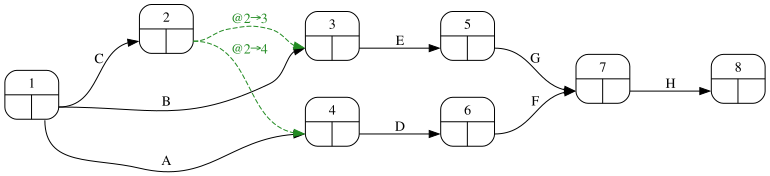

In [11]:
#| fig-cap: "Grafo PERT"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [12]:
#| tbl-cap: "Matriz de caminos"
#| label: tbl-matrizCaminos
R = proyecto.path_matrix(dummies=False)
proyecto.display_rutas("pert")

,A,B,C,D,E,F,G,H
Route_1,1,0,0,1,0,1,0,1
Route_2,0,1,0,0,1,0,1,1
Route_3,0,0,1,1,0,1,0,1
Route_4,0,0,1,0,1,0,1,1


## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  

In [14]:
T = escenarios.loc[R.columns]
duraciones_rutas = R @ T
from pmule import display_producto_rutas
display_producto_rutas(R, T, duraciones_rutas)

<IPython.core.display.Math object>

In [15]:
#| tbl-cap: "Duración de cada ruta en cada escenario"
#| label: tbl-duracionesRutas
duraciones_rutas

,optimista,normal,pesimista
Route_1,11,15,23
Route_2,22,24,33
Route_3,11,14,20
Route_4,23,25,34


Cada columna de R·T es el vector de duraciones de las rutas para un escenario: la fila r, columna s, es la suma de las duraciones (en el escenario s) de las actividades de la ruta r.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  

In [17]:
resumen = pd.DataFrame({'duración del proyecto': duraciones_rutas.max(), 'ruta crítica': duraciones_rutas.idxmax()})
resumen['actividades'] = [' - '.join(R.columns[R.loc[r] == 1]) for r in resumen['ruta crítica']]
resumen

,duración del proyecto,ruta crítica,actividades
optimista,23,Route_4,C - E - G - H
normal,25,Route_4,C - E - G - H
pesimista,34,Route_4,C - E - G - H


In [18]:
Markdown('La ruta crítica ' + ('es la misma en los tres escenarios.' if resumen['ruta crítica'].nunique() == 1 else 'cambia de un escenario a otro: la ruta más larga depende de las duraciones, no sólo de la forma del grafo.'))

La ruta crítica es la misma en los tres escenarios.

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  

En Monte Carlo cada réplica es un escenario: la matriz T tiene una columna por réplica (miles de columnas) y R·T da de una vez la duración de todas las rutas en todas las réplicas; el máximo de cada columna es la duración del proyecto en esa réplica. Con tres columnas el cálculo se hace a mano; con diez mil lo hace el ordenador, pero la operación es idéntica.